# NGC 3198: Dark Matter Halo Profile Fitting
This notebook compares the NFW and Pseudo-Isothermal halo models for the observed galaxy rotation curve of NGC 3198.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import least_squares, brentq
from scipy.stats import chi2 as chi2_dist, norm

G = 4.30091e-6  # kpc (km/s)^2 / solar mass

upsilon_disk = 0.5 # stellar mass-to-light ratio at 3.6 µm [Msun/Lsun]. Standard SPARC value (Lelli, McGaugh & Schombert 2016)
upsilon_bulge = 0.7 # unused. vbul = 0 at every radius

plt.rcParams["figure.figsize"] = (14, 8)
plt.rcParams["axes.grid"] = True

## Loading SPARC data for NGC 3198

### Data conventions and assumptions
We use the SPARC rotation-curve data for NGC 3198 consisting of the measurements with their respective quoted velocity uncertainties. The galaxy distance is fixed at 13.8 Mpc (from the SPARC file header). The stellar disk mass-to-light ratio is fixed at 0.5. The baryonic and dark matter contributions are combined assuming circular motion. We compare NFW and Pseudo-Isothermal halo profiles under these assumptions, without initially varying the stellar mass-to-light ratio.

In [2]:
filename = "sparc_data/NGC3198_rotmod.dat"
data = np.loadtxt(filename)

In [3]:
NGC_3198 = {
    "radius": data[:, 0],
    "vobs": data[:, 1],
    "verr": data[:, 2],
    "vgas": data[:, 3],
    "vdisk": data[:, 4],
    "vbul": data[:, 5],
    "sbdisk": data[:, 6],
    "sbbul": data[:, 7]
}

# vgas may be negative due to geometry of gas distribution, so we use signed square.
vbar_sq = NGC_3198["vgas"] * np.abs(NGC_3198["vgas"]) + upsilon_disk * NGC_3198["vdisk"]**2 + upsilon_bulge * NGC_3198["vbul"]**2

if np.any(vbar_sq < 0):
    raise ValueError("Negative vbar_sq encountered. Check the input data and mass-to-light ratios.")

NGC_3198["vbar_sq"] = vbar_sq
NGC_3198["vbar"] = np.sqrt(vbar_sq)

print("NGC 3198 Rotation Curve Data:\n")

print(f"{'Radius':<15}{'Vobs':<15}{'Verr':<15}{'Vgas':<15}{'Vdisk':<15}{'Vbul':<15}{'SbDisk':<15}{'SbBul':<15}{'Vbar':<15}")
print(f"{('kpc'):<15}{('km/s'):<15}{('km/s'):<15}{('km/s'):<15}{('km/s'):<15}{('km/s'):<15}{('Lsun/pc^2'):<15}{('Lsun/pc^2'):<15}{('km/s'):<15}")
print("-" * 130)

for i in range(len(NGC_3198["radius"])):
    print(f"{NGC_3198['radius'][i]:<15.2f}{NGC_3198['vobs'][i]:<15.2f}{NGC_3198['verr'][i]:<15.2f}{NGC_3198['vgas'][i]:<15.2f}{NGC_3198['vdisk'][i]:<15.2f}{NGC_3198['vbul'][i]:<15.2f}{NGC_3198['sbdisk'][i]:<15.2f}{NGC_3198['sbbul'][i]:<15.2f}{NGC_3198['vbar'][i]:<15.2f}")

NGC 3198 Rotation Curve Data:

Radius         Vobs           Verr           Vgas           Vdisk          Vbul           SbDisk         SbBul          Vbar           
kpc            km/s           km/s           km/s           km/s           km/s           Lsun/pc^2      Lsun/pc^2      km/s           
----------------------------------------------------------------------------------------------------------------------------------
0.32           24.40          35.90          0.00           63.28          0.00           1084.92        0.00           44.75          
0.64           43.30          16.30          0.00           73.66          0.00           590.57         0.00           52.09          
0.96           45.50          16.10          0.00           78.98          0.00           410.97         0.00           55.85          
1.28           58.50          15.40          0.35           82.70          0.00           329.34         0.00           58.48          
1.61           68.80  

## Plotting the Rotation Curve & its Baryon Decompositions

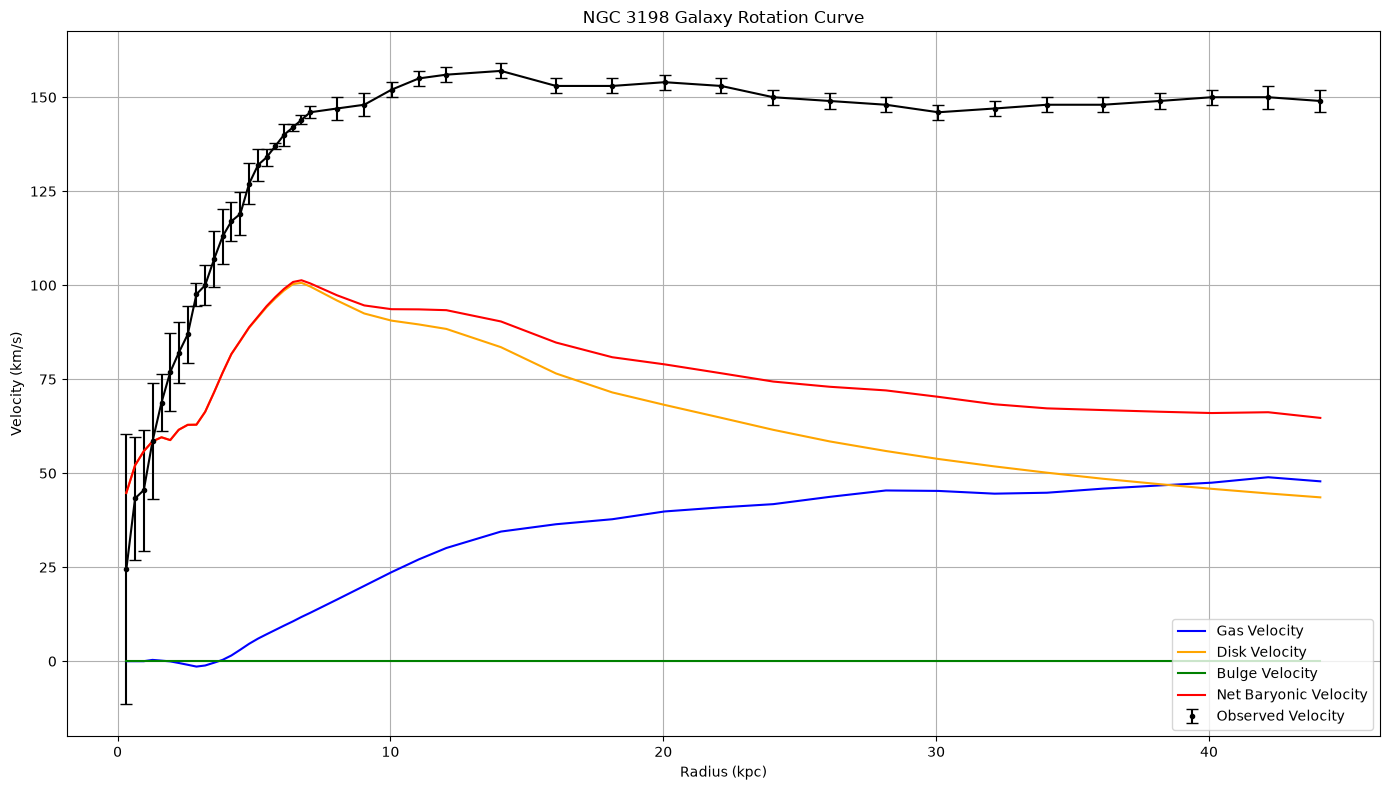

In [4]:
plt.figure()

plt.plot(NGC_3198["radius"], NGC_3198["vobs"], color='black')
plt.errorbar(NGC_3198["radius"], NGC_3198["vobs"], yerr=NGC_3198["verr"], fmt='.', color = 'black', capsize=4, label='Observed Velocity')

plt.plot(NGC_3198["radius"], NGC_3198["vgas"], label='Gas Velocity', color='blue')
plt.plot(NGC_3198["radius"], np.sqrt(upsilon_disk) * NGC_3198["vdisk"], label='Disk Velocity', color='orange')
plt.plot(NGC_3198["radius"], np.sqrt(upsilon_bulge) * NGC_3198["vbul"], label='Bulge Velocity', color='green')

plt.plot(NGC_3198["radius"], NGC_3198["vbar"], label='Net Baryonic Velocity', color='red')

plt.title('NGC 3198 Galaxy Rotation Curve')
plt.xlabel('Radius (kpc)')
plt.ylabel('Velocity (km/s)')

plt.legend()
plt.tight_layout()
plt.savefig("assets/rotation_curve_decomposition.png", dpi=300)
plt.show()

**Observations:**

Our obtained rotation curve rises roughly linearly until ~7 kpc then starts to flatten to a value of ~150 km/s. Around ~39-40 kpc, gas velocity overtakes disk velocity. At ~44 kpc, the baryons give ~65 km/s of the total ~150 km/s. Thus, the baryonic contribution (velocity squared) is only ~19%. NGC 3198 is hence a dark-matter dominated galaxy.

## Fitting NFW & Pseudo-Isothermal models on the obtained galaxy rotation curve data

### Cuspy NFW Halo Model

In [5]:
r = NGC_3198["radius"]
vobs = NGC_3198["vobs"]
verr = NGC_3198["verr"]
vbar_sq = NGC_3198["vbar_sq"]
vbar = NGC_3198["vbar"]

In [6]:
def nfw_mass(r, rho_s, r_s):
    x = r / r_s

    return 4 * np.pi * rho_s * r_s**3 * (np.log1p(x) - x / (1 + x)) # log1p(x) is used for numerical stability when x is small

def nfw_velocity(r, rho_s, r_s):
    mass = nfw_mass(r, rho_s, r_s)

    return np.sqrt(G * mass / r)

def total_nfw_velocity(params):
    rho_s = 10 ** params[0]  # Convert log10(rho_s) back to rho_s
    r_s = 10 ** params[1]  # Convert log10(r_s) back to r_s

    vhalo = nfw_velocity(r, rho_s, r_s)

    return np.sqrt(vbar_sq + vhalo**2)

def residuals_nfw(params):
    return (vobs - total_nfw_velocity(params)) / verr

In [7]:
fit_nfw = least_squares(residuals_nfw, x0=[7, np.log10(5)], bounds=([3, -2], [12, 3]), max_nfev=20000)

rhos_best = 10 ** fit_nfw.x[0]
rs_best = 10 ** fit_nfw.x[1]

vmodel_nfw = total_nfw_velocity(fit_nfw.x)

chi2_nfw = np.sum(residuals_nfw(fit_nfw.x) ** 2)
dof_nfw = len(vobs) - len(fit_nfw.x)
reduced_chi2_nfw = chi2_nfw / dof_nfw

if fit_nfw.success:
    print("Optimization was successful.")

    print("\nBest-fit parameters for NGC 3198 (NFW Halo Profile):")
    print(f"rho_s: {rhos_best:.2e} M_sun/kpc^3")
    print(f"r_s: {rs_best:.2f} kpc")
    print(f"χ²: {chi2_nfw:.2f}")
    print(f"Reduced χ²: {reduced_chi2_nfw:.2f}")
    print(f"Degrees of freedom: {dof_nfw}")
else:
    print("Optimization failed.")
    print(f"Message: {fit_nfw.message}")

Optimization was successful.

Best-fit parameters for NGC 3198 (NFW Halo Profile):
rho_s: 5.71e+06 M_sun/kpc^3
r_s: 16.31 kpc
χ²: 57.09
Reduced χ²: 1.39
Degrees of freedom: 41


**NFW result:**

An r_s value of 16.31 kpc shows that our observed data (~44 kpc) extends well beyond the scale radius for the obtained NFW model. A reduced χ² value of 1.39 shows it's a reasonable fit but needs to be looked further into.

#### Plotting Observed vs NFW Model Rotation Curves

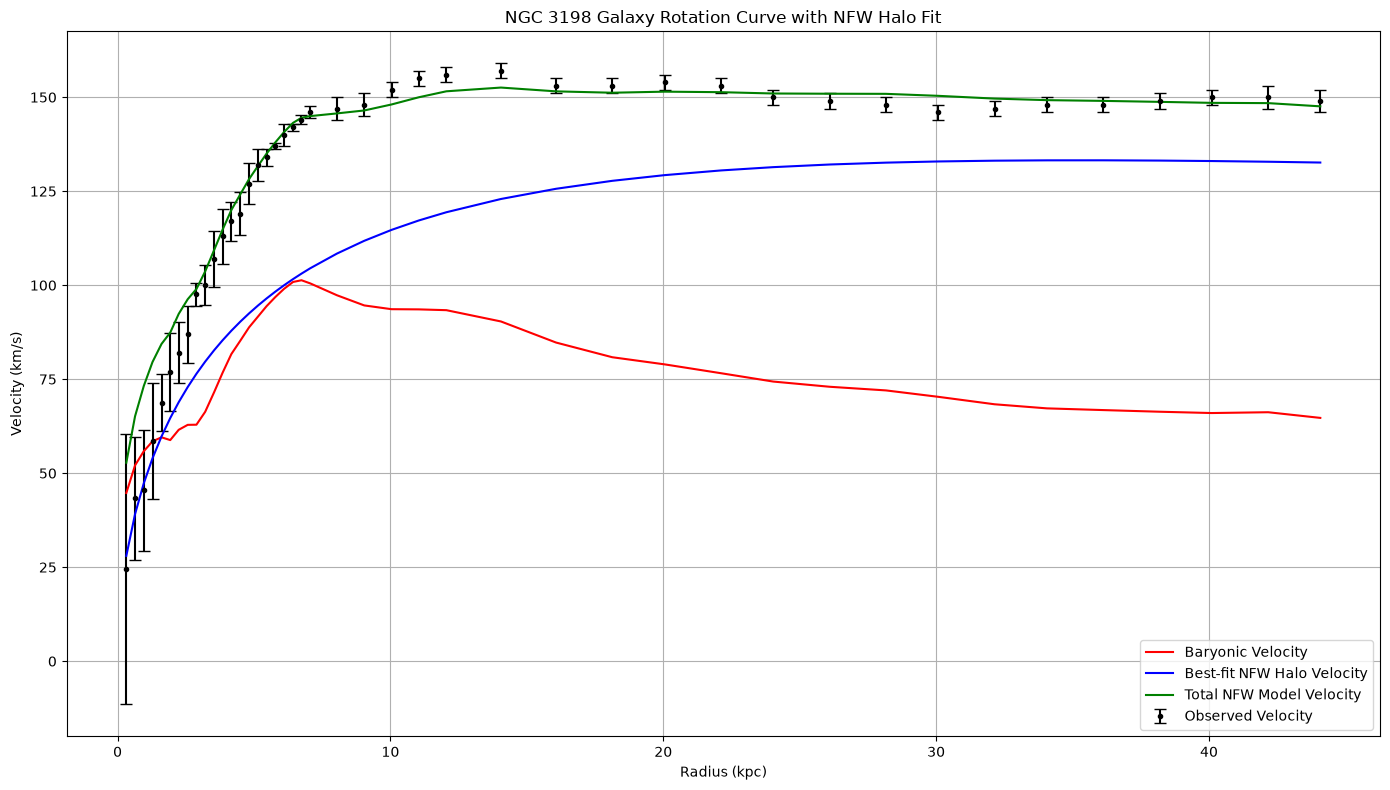

In [8]:
v_halo_best_nfw = nfw_velocity(r, rhos_best, rs_best)

normalized_residuals_nfw = (vobs - vmodel_nfw) / verr

# NFW Halo Fit Plot

plt.figure()

plt.errorbar(r, vobs, yerr=verr, fmt='.', color='black', capsize=4, label='Observed Velocity')

plt.plot(r, vbar, label='Baryonic Velocity', color='red')
plt.plot(r, v_halo_best_nfw, label='Best-fit NFW Halo Velocity', color='blue')
plt.plot(r, vmodel_nfw, label='Total NFW Model Velocity', color='green')

plt.title('NGC 3198 Galaxy Rotation Curve with NFW Halo Fit')
plt.xlabel('Radius (kpc)')
plt.ylabel('Velocity (km/s)')

plt.legend()
plt.tight_layout()
plt.savefig("assets/nfw_fit.png", dpi=300)
plt.show()

**Observations:**

In this obtained model, around ~1.6 kpc, the halo contribution overtakes the baryonic contribution and it stays that way for the rest of our data. We can also roughly see the NFW halo velocity peaking at about 30-35 kpc but it's a very flat peak.

#### Residual & Normalized Residual Plots (NFW Model)

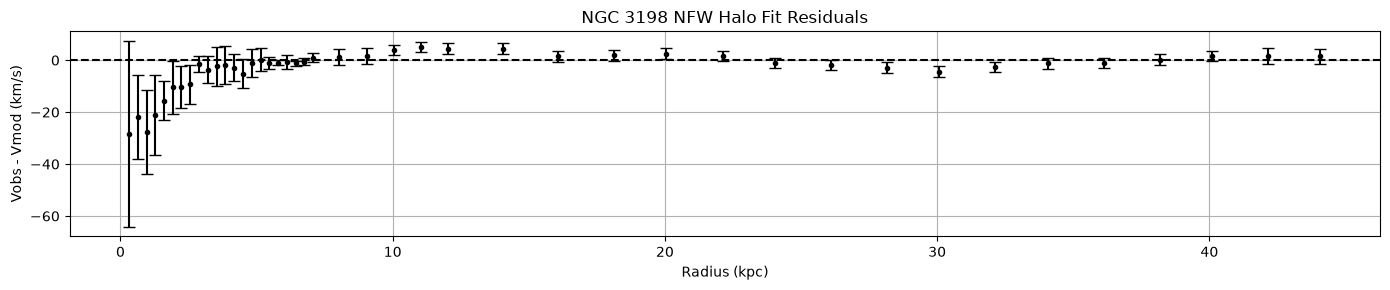

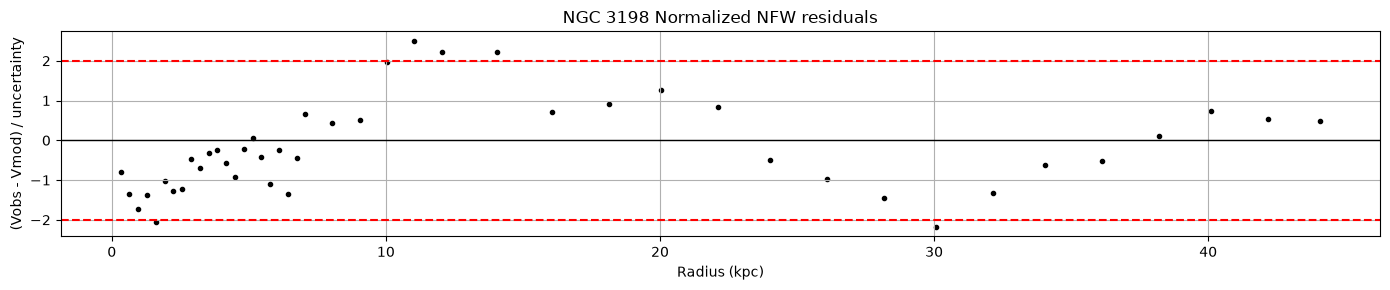

In [9]:
# Residuals Plot

plt.figure(figsize=(14, 3))

plt.axhline(0, color='black', ls='--')
plt.errorbar(r, vobs - vmodel_nfw, yerr=verr, fmt='.', color='black', capsize=4)

plt.title('NGC 3198 NFW Halo Fit Residuals')
plt.xlabel('Radius (kpc)')
plt.ylabel('Vobs - Vmod (km/s)')

plt.tight_layout()
plt.show()

# Normalized Residuals Plot

plt.figure(figsize=(14, 3))

plt.axhline(0, color="black", linewidth=1)
plt.axhline(2, color="red", linestyle="--")
plt.axhline(-2, color="red", linestyle="--")

plt.scatter(r, normalized_residuals_nfw, color='black', marker = '.')

plt.title("NGC 3198 Normalized NFW residuals")
plt.xlabel("Radius (kpc)")
plt.ylabel("(Vobs - Vmod) / uncertainty")

plt.tight_layout()
plt.savefig("assets/nfw_normalized_residuals.png", dpi=300)
plt.show()

**NFW residuals:**

The residuals seem to follow a wave-like pattern, systematically overpredicting and underpredicting the data for several consecutive data points. Thus, the obtained residuals are not random and require further diagnostics.

### Cored Pseudo-Isothermal Model

In [10]:
def core_mass(r, rho0, rc):
    x = r / rc

    return 4 * np.pi * rho0 * rc**3 * (x - np.arctan(x))

def core_velocity(r, rho0, rc):
    mass = core_mass(r, rho0, rc)

    return np.sqrt(G * mass / r)

def total_core_velocity(params):
    rho0 = 10**params[0]
    rc = 10**params[1]

    vhalo = core_velocity(r, rho0, rc)

    return np.sqrt(vbar_sq + vhalo**2)


def residuals_core(params):
    return (vobs - total_core_velocity(params)) / verr

In [11]:
fit_core = least_squares(residuals_core, x0=[7, np.log10(5)], bounds=([3, -2], [12, 3]), max_nfev=20000)

rho0_best = 10 ** fit_core.x[0]
rc_best = 10 ** fit_core.x[1]

vmodel_core = total_core_velocity(fit_core.x)

chi2_core = np.sum(residuals_core(fit_core.x) ** 2)
dof_core = len(vobs) - len(fit_core.x)
reduced_chi2_core = chi2_core / dof_core

if fit_core.success:
    print("Optimization was successful.")

    print("\nBest-fit parameters for NGC 3198 (Pseudo-Isothermal Halo Profile):")
    print(f"rho0: {rho0_best:.3g} M_sun/kpc^3")
    print(f"rc: {rc_best:.2f} kpc")
    print(f"χ²: {chi2_core:.2f}")
    print(f"Reduced χ²: {reduced_chi2_core:.2f}")
    print(f"Degrees of freedom: {dof_core}")
else:
    print("Optimization failed.")
    print(f"Message: {fit_core.message}")

Optimization was successful.

Best-fit parameters for NGC 3198 (Pseudo-Isothermal Halo Profile):
rho0: 5.3e+07 M_sun/kpc^3
rc: 2.66 kpc
χ²: 49.89
Reduced χ²: 1.22
Degrees of freedom: 41


**Pseudo-Isothermal result:**

The rc value of 2.66 kpc lies well within our observed data and is reasonable for a spiral galaxy. The reduced χ² value of 1.22 hints the Pseudo-Isothermal model might be a better fit to our data than the NFW model earlier.

#### Plotting Observed vs Pseudo-Isothermal Model

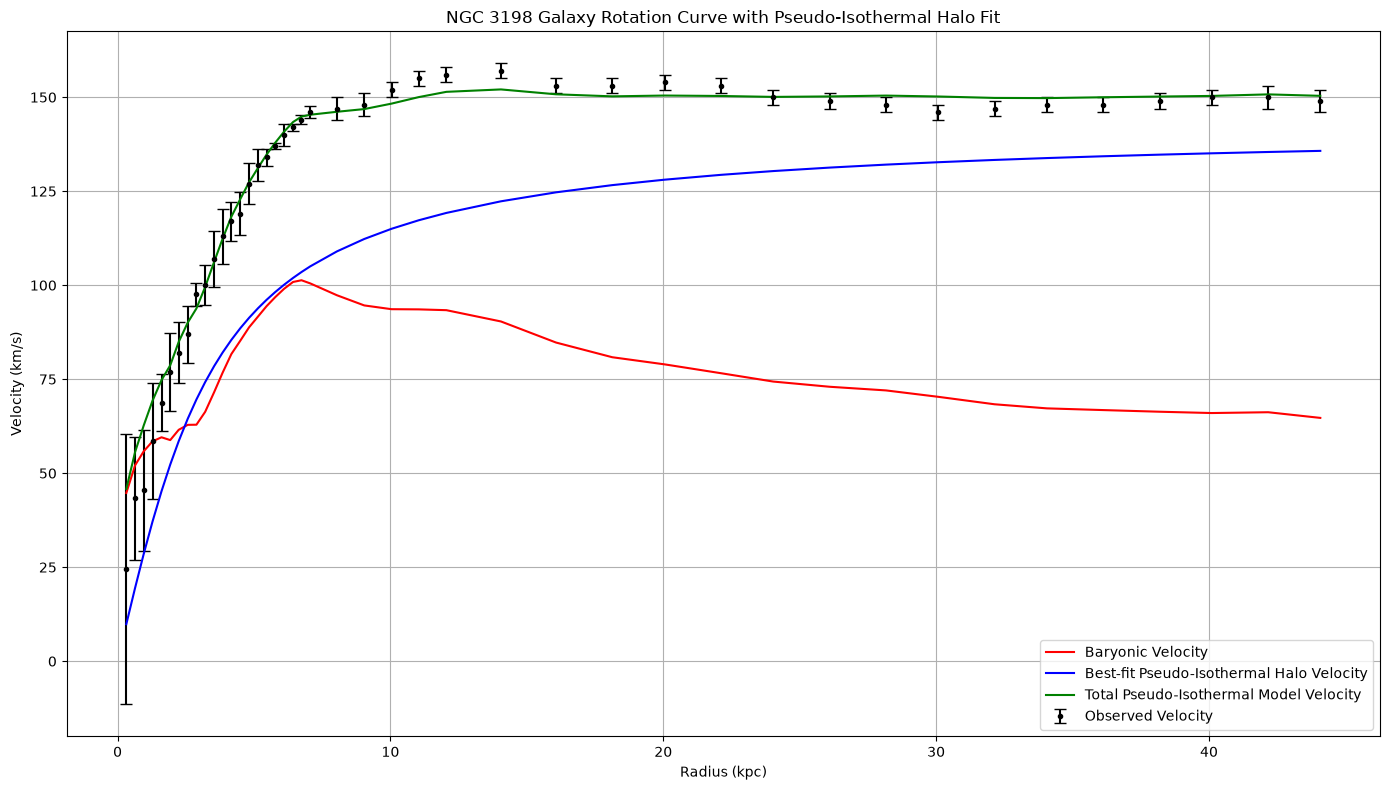

In [12]:
v_halo_best_core = core_velocity(r, rho0_best, rc_best)

normalized_residuals_core = (vobs - vmodel_core) / verr

# Core Halo Fit Plot

plt.figure()

plt.errorbar(r, vobs, yerr=verr, fmt='.', color='black', capsize=4, label='Observed Velocity')

plt.plot(r, vbar, label='Baryonic Velocity', color='red')
plt.plot(r, v_halo_best_core, label='Best-fit Pseudo-Isothermal Halo Velocity', color='blue')
plt.plot(r, vmodel_core, label='Total Pseudo-Isothermal Model Velocity', color='green')

plt.title('NGC 3198 Galaxy Rotation Curve with Pseudo-Isothermal Halo Fit')
plt.xlabel('Radius (kpc)')
plt.ylabel('Velocity (km/s)')

plt.legend()
plt.tight_layout()
plt.savefig("assets/pseudo_isothermal_fit.png", dpi=300)
plt.show()

**Observations:**

The halo velocity overtakes the baryonic velocity at about ~2.5 kpc. Unlike the NFW model, we can see Pseudo-Isothermal model gradually approaching a value at higher r instead of peaking anywhere.

#### Residual & Normalized Residual Plots (Pseudo-Isothermal Model)

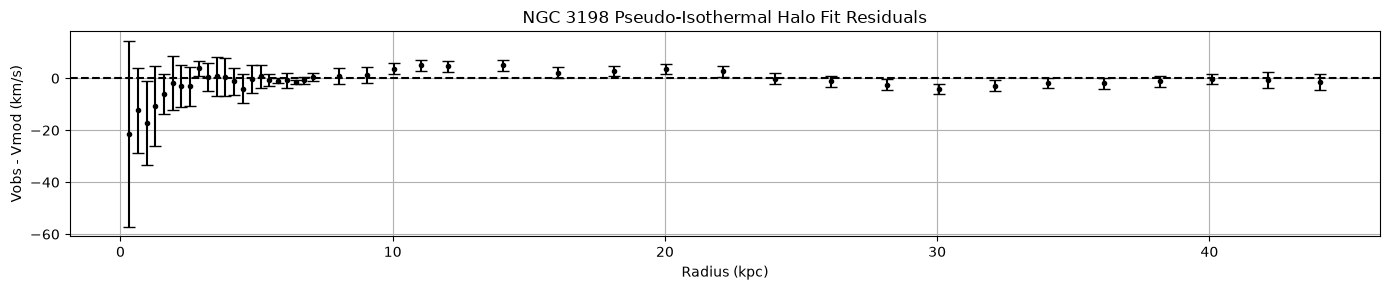

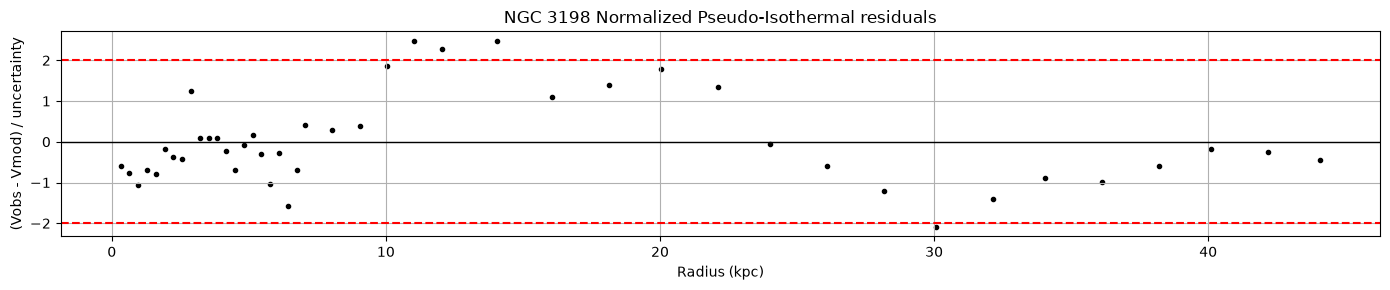

In [13]:
# Residuals Plot

plt.figure(figsize=(14, 3))

plt.axhline(0, color='black', ls='--')
plt.errorbar(r, vobs - vmodel_core, yerr=verr, fmt='.', color='black', capsize=4)

plt.title('NGC 3198 Pseudo-Isothermal Halo Fit Residuals')
plt.xlabel('Radius (kpc)')
plt.ylabel('Vobs - Vmod (km/s)')

plt.tight_layout()
plt.show()

# Normalized Residuals Plot

plt.figure(figsize=(14, 3))

plt.axhline(0, color="black", linewidth=1)
plt.axhline(2, color="red", linestyle="--")
plt.axhline(-2, color="red", linestyle="--")

plt.scatter(r, normalized_residuals_core, color='black', marker = '.')

plt.title("NGC 3198 Normalized Pseudo-Isothermal residuals")
plt.xlabel("Radius (kpc)")
plt.ylabel("(Vobs - Vmod) / uncertainty")

plt.tight_layout()
plt.savefig("assets/pseudo_isothermal_normalized_residuals.png", dpi=300)
plt.show()

Even for the Pseudo-Isothermal model, the residuals don't seem random. For multiple data points, they are on the same side. This requires further investigation.

## Diagnostics

In [14]:
H0 = 0.070  # km/s/kpc
rho_crit = 3 * H0 ** 2 / (8 * np.pi * G)  # Msun/kpc^3

R200 = brentq(lambda R: nfw_mass(R, rhos_best, rs_best) / (4/3 * np.pi * R **3) - 200 * rho_crit, 1, 5000)

print("Size, Mass and Structure of the obtained NFW Halo Model:")
print(f"   R200: {R200:.0f} kpc")
print(f"   M200: {nfw_mass(R200, rhos_best, rs_best):.2e} Msun")
print(f"   c200: {R200/rs_best:.1f}")

Size, Mass and Structure of the obtained NFW Halo Model:
   R200: 159 kpc
   M200: 4.57e+11 Msun
   c200: 9.7


The NFW model gives us a c200 of 9.7 and M200 of ~4.6e+11 Msun which is typical for a galaxy like NGC 3198.

In [15]:
def fit_report(fit, labels, name):
    J = fit.jac

    cov = np.linalg.inv(J.T @ J)              # residuals are already divided by verr
    err = np.sqrt(np.diag(cov))               # 1-sigma errors on log10(parameters)
    
    corr = cov[0, 1] / (err[0] * err[1])
    chi2 = 2 * fit.cost
    dof = len(vobs) - len(fit.x)

    print(name, ":", sep = "")
    print(f"  χ² = {chi2:.2f}, dof = {dof}, reduced = {chi2/dof:.2f}, p-value = {chi2_dist.sf(chi2, dof):.2g}")
    for lab, val, e in zip(labels, fit.x, err):
        print(f"  log10({lab}) = {val:.2f} +/- {e:.2f}  ->  {lab} = {10**val:.3g}  (x/÷ {10**e:.2f})")
    print(f"  Correlation of the two parameters (log10): {corr:+.4f}\n")

fit_report(fit_nfw,  ["rho_s", "r_s"], "NFW")
fit_report(fit_core, ["rho_0", "r_c"], "Pseudo-Isothermal")

NFW:
  χ² = 57.09, dof = 41, reduced = 1.39, p-value = 0.049
  log10(rho_s) = 6.76 +/- 0.02  ->  rho_s = 5.71e+06  (x/÷ 1.05)
  log10(r_s) = 1.21 +/- 0.01  ->  r_s = 16.3  (x/÷ 1.03)
  Correlation of the two parameters (log10): -0.9888

Pseudo-Isothermal:
  χ² = 49.89, dof = 41, reduced = 1.22, p-value = 0.16
  log10(rho_0) = 7.72 +/- 0.02  ->  rho_0 = 5.3e+07  (x/÷ 1.05)
  log10(r_c) = 0.42 +/- 0.01  ->  r_c = 2.66  (x/÷ 1.03)
  Correlation of the two parameters (log10): -0.9889



**NFW Model:** Both parameters are uncertain by x/÷ 1.05 for p_s and x/÷ 1.03 for r_s and almost perfectly anti-correlated (-0.9888). This means the data might be fixing a certain combination of both parameters where some change in one can be made up for by another parameter. This again requires further investigation.

**Pseudo-Isothermal Model:** Both parameters are uncertain by x/÷ 1.05 for p0 and x/÷ 1.03 for r_c and almost perfectly anti-correlated (-0.9889). This indicates that for this model too, the data might only be fixing a certain combination of the two parameters. This thus needs to be further investigated.

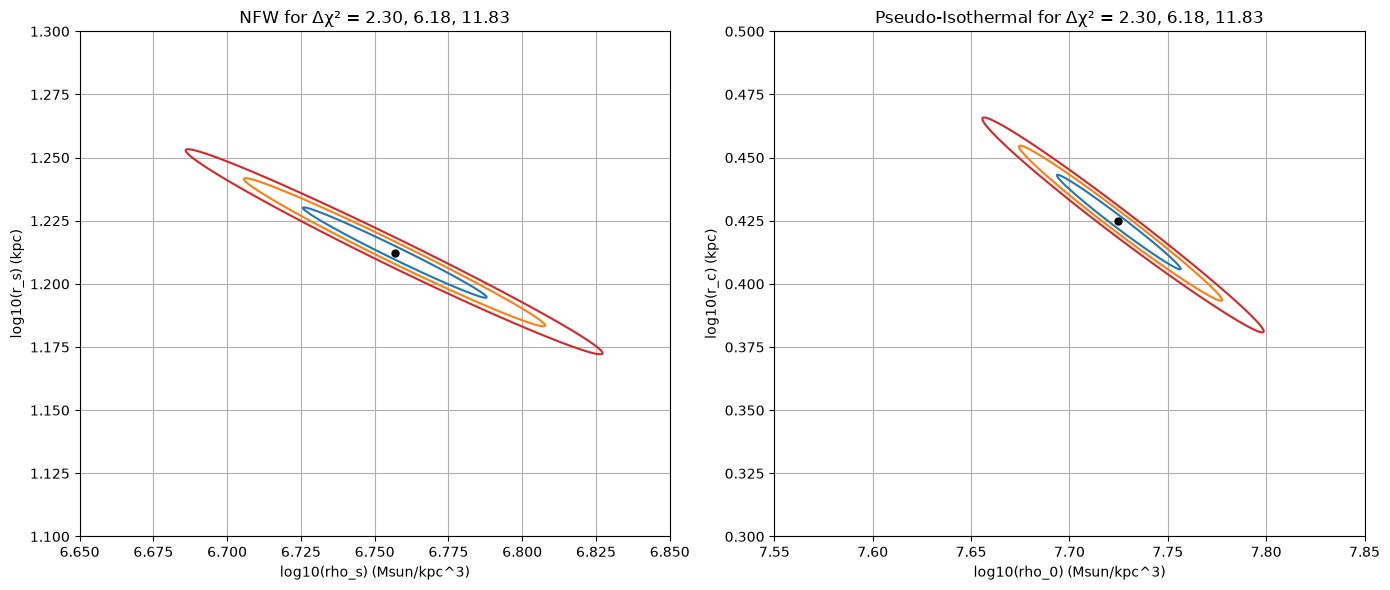

In [16]:
def chi2_grid(resid, lrho, lrs):
    return np.array([[np.sum(resid([a, b])**2) for a in lrho] for b in lrs])

levels = [2.30, 6.18, 11.83]     # 1, 2, 3 sigma for 2 free parameters

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, resid, fit, ttl, (xr, yr) in [
        (axes[0], residuals_nfw, fit_nfw, "NFW", ((6.65, 6.85), (1.1, 1.3))),
        (axes[1], residuals_core, fit_core, "Pseudo-Isothermal", ((7.55, 7.85), (0.3, 0.5)))]:
    
    lrho = np.linspace(*xr, 2000)
    lrs = np.linspace(*yr, 2000)
    grid = chi2_grid(resid, lrho, lrs)

    ax.contour(lrho, lrs, grid - 2*fit.cost, levels=levels, colors=["C0", "C1", "C3"])

    ax.plot(*fit.x, 'o', ms=5, color='black')

    ax.set_title(f"{ttl} for Δχ² = 2.30, 6.18, 11.83")

axes[0].set_xlabel("log10(rho_s) (Msun/kpc^3)")
axes[0].set_ylabel("log10(r_s) (kpc)")

axes[1].set_xlabel("log10(rho_0) (Msun/kpc^3)")
axes[1].set_ylabel("log10(r_c) (kpc)")

plt.tight_layout()
plt.savefig("assets/chi2_contours.png", dpi=300)
plt.show()

In [17]:
def residual_diagnostics(res, name):
    s = np.sign(res)
    runs = 1 + np.sum(s[1:] != s[:-1])

    n1, n2 = (s > 0).sum(), (s < 0).sum()
    mu = 2*n1*n2/(n1+n2) + 1

    var = (mu - 1)*(mu - 2)/(n1 + n2 - 1)
    z = (runs - mu)/np.sqrt(var)

    lag1 = np.corrcoef(res[:-1], res[1:])[0, 1]

    print(f"{name} Model:")
    print(f"  Runs Test: {runs} runs (expected {mu:.1f})")
    print(f"  z-score: {z:.1f}")
    print(f"  p-value: {norm.cdf(z):.1e}")
    print(f"  Lag-1 autocorrelation: {lag1:+.2f}")
    print(f"  Points beyond 2 σ: {(abs(res) > 2).sum()}\n")

residual_diagnostics(normalized_residuals_nfw,  "NFW")
residual_diagnostics(normalized_residuals_core, "Pseudo-Isothermal")

NFW Model:
  Runs Test: 6 runs (expected 21.1)
  z-score: -5.0
  p-value: 3.0e-07
  Lag-1 autocorrelation: +0.83
  Points beyond 2 σ: 5

Pseudo-Isothermal Model:
  Runs Test: 7 runs (expected 21.1)
  z-score: -4.7
  p-value: 1.6e-06
  Lag-1 autocorrelation: +0.80
  Points beyond 2 σ: 4



**Parameter Degeneracy & Fit Quality:**

**NFW Model:** The NFW parameters are highly anti-correlated (-0.9888) and the contour plots show a long, tilted ellipse even though our data extends well beyond the r_s value of 16.31 kpc. This indicates that our data (because of its sample size) only constrains roughly p_s.r_s^a with a little deviation for some value of a instead of both the parameters independently. The fit is acceptable but not good (reduced χ² = 1.39). The residuals are themselves strongly correlated (lag1 correlation 0.83) so the formal parameter uncertainties are likely underestimated.

**Pseudo-Isothermal Model:** The Pseudo-Isothermal parameters are also almost perfectly anti-correlated (-0.9889) and the contour plots show a similar long and tilted ellipse. We only have 2-3 data points for r << r_c, which have huge error bars and in that region, the baryonic contribution exceeds the halo gravitational contribution. Hence the model only fixes p0.r_c^2 (r >> r_c) and p0 (r ~ r_c). At r >> r_c, any small error in the value of r_c shifts the error in p0 twice as much in the opposite direction. The large lag1 correlation also shows that the residuals are highly correlated and hence, the reported uncertainties might be optimistic.

## Comparing NFW vs Pseudo-Isothermal Model

Comparative Analysis of Halo Models for NGC 3198:

Model                       NFW    Pseudo-Isothermal
χ²                        57.09                49.89
Reduced χ²                 1.39                 1.22


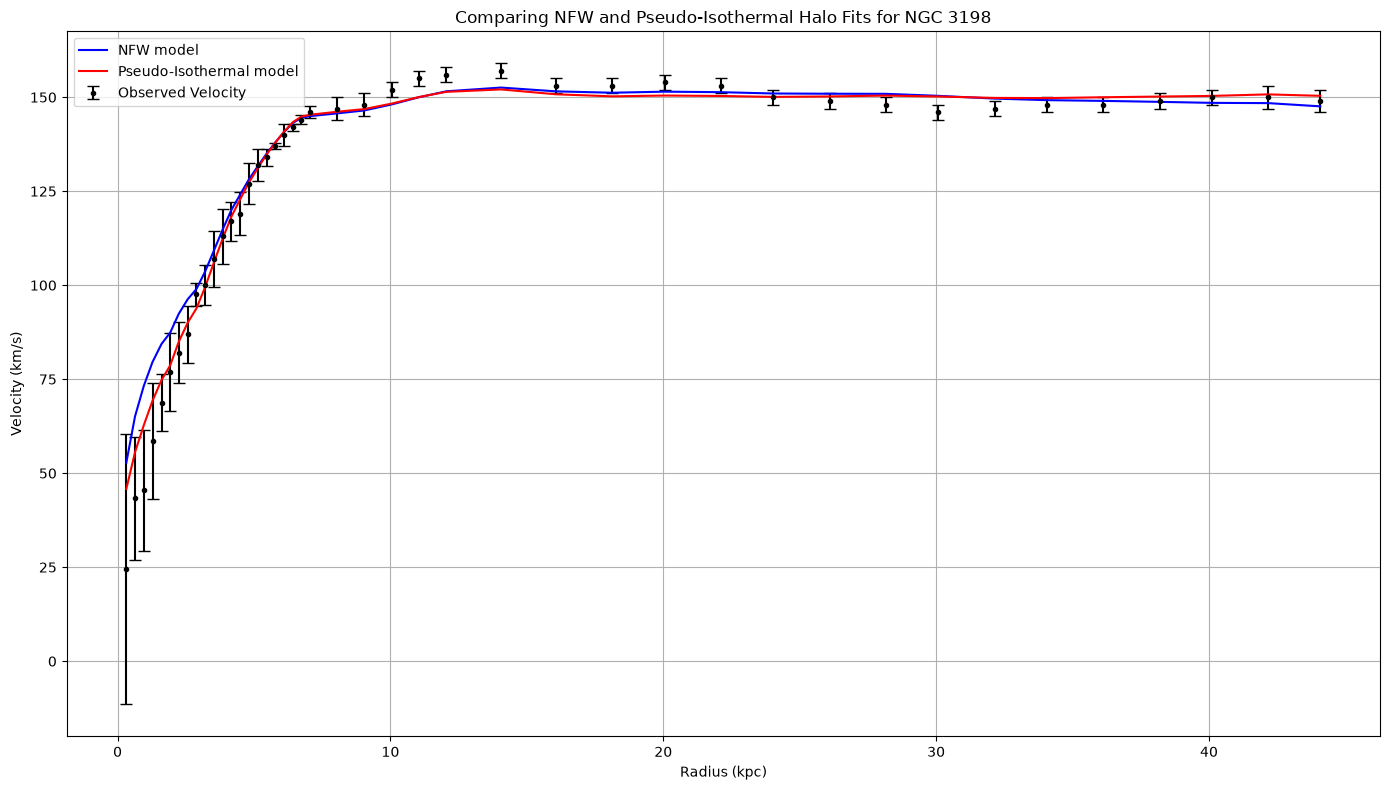

In [18]:
comparison = {
    "NFW": {
        "chi2": chi2_nfw,
        "reduced_chi2": reduced_chi2_nfw
    },
    "Pseudo-Isothermal": {
        "chi2": chi2_core,
        "reduced_chi2": reduced_chi2_core
    }
}

print("Comparative Analysis of Halo Models for NGC 3198:\n")

print(f"{'Model':<20} {'NFW':>10} {'Pseudo-Isothermal':>20}")
print(f"{'χ²':<20} {comparison['NFW']['chi2']:>10.2f} {comparison['Pseudo-Isothermal']['chi2']:>20.2f}")
print(f"{'Reduced χ²':<20} {comparison['NFW']['reduced_chi2']:>10.2f} {comparison['Pseudo-Isothermal']['reduced_chi2']:>20.2f}")

# Plotting both models together for comparison

plt.figure()

plt.errorbar(r, vobs, yerr=verr, fmt=".", color="black", capsize=4, label="Observed Velocity")

plt.plot(r, vmodel_nfw, label="NFW model", color="blue")
plt.plot(r, vmodel_core, label="Pseudo-Isothermal model", color="red")

plt.title("Comparing NFW and Pseudo-Isothermal Halo Fits for NGC 3198")
plt.xlabel("Radius (kpc)")
plt.ylabel("Velocity (km/s)")

plt.legend()
plt.tight_layout()
plt.savefig("assets/model_comparison.png", dpi=300)
plt.show()

## Testing our Mass-to-Light assumptions

In [19]:
def fit_fixed_upsilon(mass_func, upsilon, x0):
    def resid(p):
        v2 = NGC_3198["vgas"]*np.abs(NGC_3198["vgas"]) + upsilon*NGC_3198["vdisk"]**2 + G*mass_func(r, 10**p[0], 10**p[1])/r
        v = np.sqrt(np.clip(v2, 0, None))

        return (vobs - v)/verr

    f = least_squares(resid, x0, bounds=([3, -2], [12, 3]))

    return f.x, 2*f.cost, f.success

upsilon_grid = np.linspace(0.1, 1.2, 100)
upsilon_sweep = {}

prior_lo = upsilon_disk*10**-0.1
prior_hi = upsilon_disk*10**0.1

for name, M in [("NFW", nfw_mass), ("Pseudo-Isothermal", core_mass)]:
    x0 = [7, 0.7]
    chi2_values, scale_radii, converged = [], [], []

    for u in upsilon_grid:
        x, c2, success = fit_fixed_upsilon(M, u, x0)
        x0 = list(x)   # warm start from the previous fit

        chi2_values.append(c2)
        scale_radii.append(10**x[1])
        converged.append(success)

    upsilon_sweep[name] = {
        "chi2": np.array(chi2_values),
        "scale_radius": np.array(scale_radii),
        "converged": all(converged)
    }

for name, s in upsilon_sweep.items():
    allowed = upsilon_grid[s["chi2"] - s["chi2"].min() < 1]

    print(f"{name} Model:")
    print(f"  Y_disk = {upsilon_grid[np.argmin(s['chi2'])]:.2f} (χ² within 1σ of minimum: {allowed.min():.2f} to {allowed.max():.2f})")
    print(f"  χ² (no prior) = {s['chi2'].min():.1f}")
    print(f"  All fits converged = {s['converged']}\n")

gap = upsilon_sweep["NFW"]["chi2"] - upsilon_sweep["Pseudo-Isothermal"]["chi2"]

print("χ² gap (NFW - Pseudo-Isothermal):")
for u in [prior_lo, upsilon_disk, prior_hi]:
    print(f"  Y_disk = {u:.2f}: {np.interp(u, upsilon_grid, gap):+.1f}")

NFW Model:
  Y_disk = 0.46 (χ² within 1σ of minimum: 0.42 to 0.49)
  χ² (no prior) = 55.5
  All fits converged = True

Pseudo-Isothermal Model:
  Y_disk = 0.51 (χ² within 1σ of minimum: 0.49 to 0.56)
  χ² (no prior) = 49.7
  All fits converged = True

χ² gap (NFW - Pseudo-Isothermal):
  Y_disk = 0.40: -5.4
  Y_disk = 0.50: +7.2
  Y_disk = 0.63: +24.4


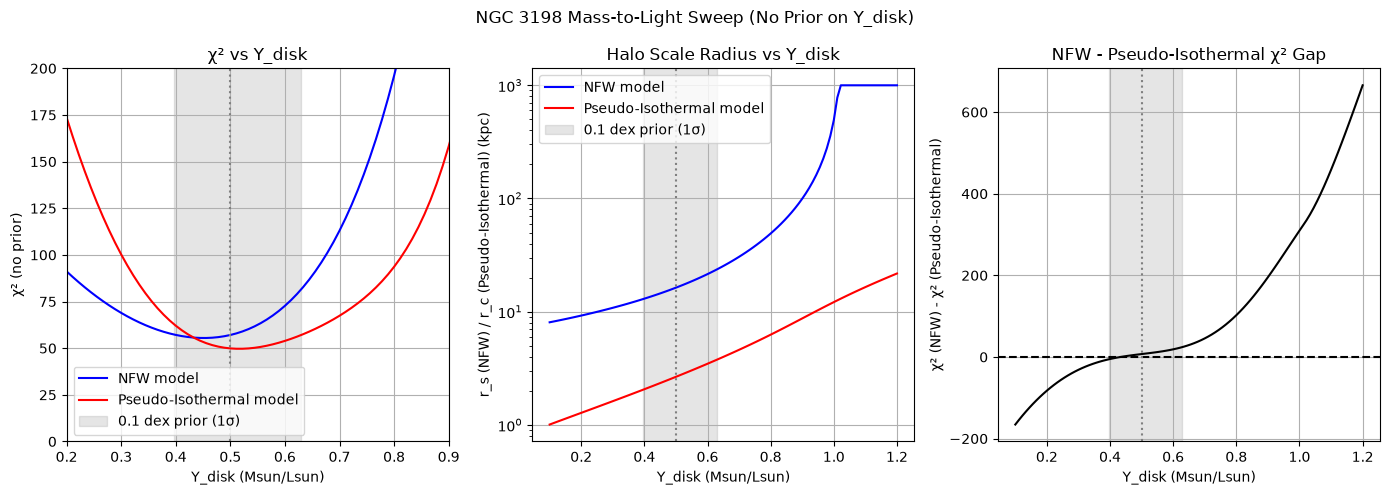

In [20]:
# Mass-to-Light Sweep Plots

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# chi2 vs Y_disk
axes[0].plot(upsilon_grid, upsilon_sweep["NFW"]["chi2"], color='blue', label='NFW model')
axes[0].plot(upsilon_grid, upsilon_sweep["Pseudo-Isothermal"]["chi2"], color='red', label='Pseudo-Isothermal model')

axes[0].set_title('χ² vs Y_disk')
axes[0].set_xlabel('Y_disk (Msun/Lsun)')
axes[0].set_ylabel('χ² (no prior)')

# Halo scale radius vs Y_disk
axes[1].plot(upsilon_grid, upsilon_sweep["NFW"]["scale_radius"], color='blue', label='NFW model')
axes[1].plot(upsilon_grid, upsilon_sweep["Pseudo-Isothermal"]["scale_radius"], color='red', label='Pseudo-Isothermal model')
axes[1].set_yscale('log')

axes[1].set_title('Halo Scale Radius vs Y_disk')
axes[1].set_xlabel('Y_disk (Msun/Lsun)')
axes[1].set_ylabel('r_s (NFW) / r_c (Pseudo-Isothermal) (kpc)')

# Chi-squared gap between the two models
axes[2].plot(upsilon_grid, gap, color='black')
axes[2].axhline(0, color='black', ls='--')

axes[2].set_title('NFW - Pseudo-Isothermal χ² Gap')
axes[2].set_xlabel('Y_disk (Msun/Lsun)')
axes[2].set_ylabel('χ² (NFW) - χ² (Pseudo-Isothermal)')

for ax in axes:
    ax.axvspan(prior_lo, prior_hi, color='gray', alpha=0.2, label='0.1 dex prior (1σ)')
    ax.axvline(upsilon_disk, color='gray', ls=':')

axes[0].set_xlim(0.2, 0.9)
axes[0].set_ylim(0, 200)   # zoom in on the minima

axes[0].legend()
axes[1].legend()

fig.suptitle('NGC 3198 Mass-to-Light Sweep (No Prior on Y_disk)')
plt.tight_layout()
plt.savefig("assets/mass_to_light_sweep.png", dpi=300)
plt.show()

**Observations:**

With no prior, the minimum χ² is at Y_disk ~0.46 for NFW and ~0.51 for Pseudo-Isothermal, with χ² within 1 of the minimum for 0.42-0.49 and 0.49-0.56 respectively. The NFW range lies really close to it and the Pseudo-Isothermal model range includes the fixed value of 0.5. So we can conclude that the data alone approximately agrees with the standard SPARC assumption.

The halo scale radius increases with Y_disk for both models. The NFW scale radius saturates at its upper bound of 1000 kpc for Y_disk > ~1.0, which is a fitting limit and not physical.

We also see that the preference for the cored model depends on Y_disk. The NFW model is preferred at Y_disk < ~0.43 and the Pseudo-Isothermal model is preferred above it by del χ² ~7 at 0.5 and ~24 at 0.63.

## Extrapolating the NFW and Pseudo-Isothermal Models

NFW: At 159 kpc, the envelope spans 108.4-114.1 km/s
Pseudo-Isothermal: At 159 kpc, the envelope spans 138.6-142.5 km/s


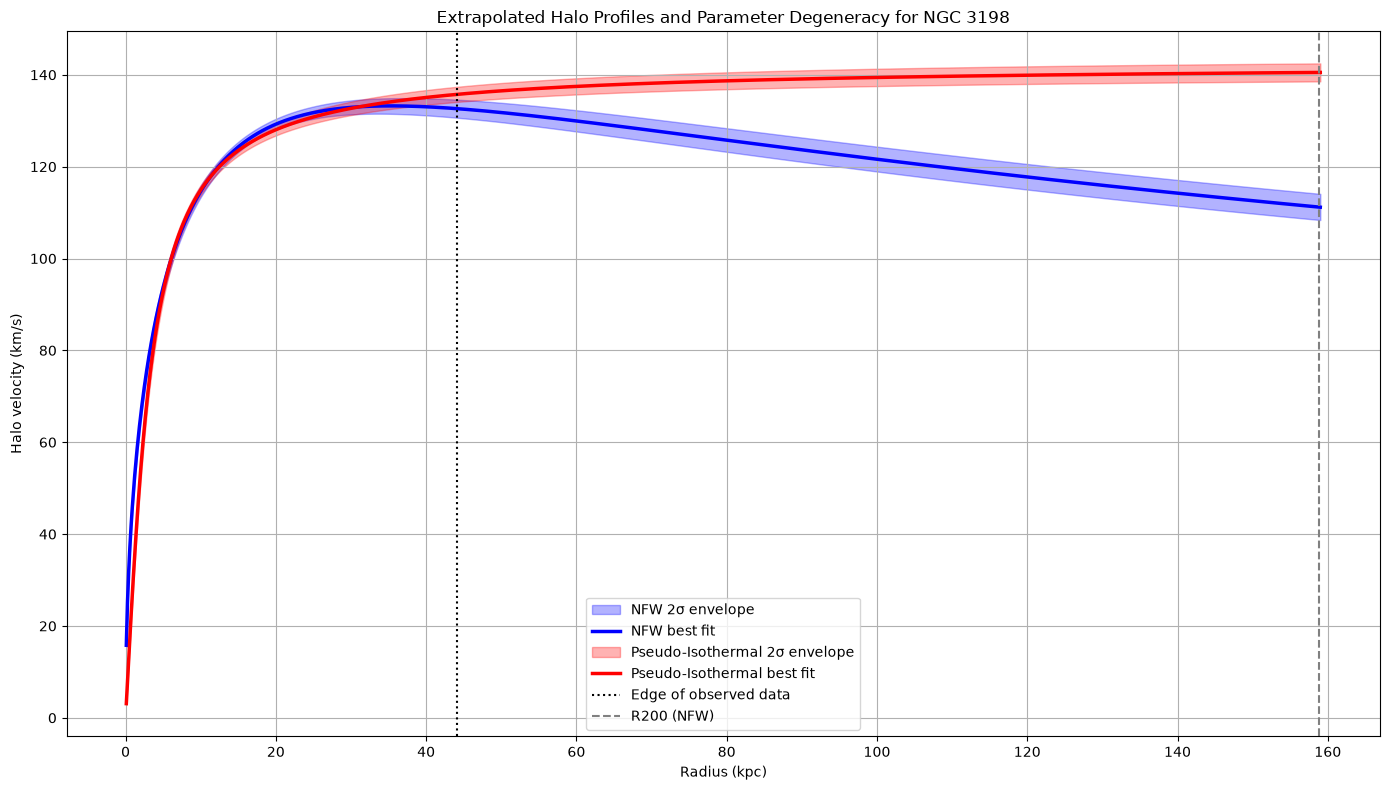

In [21]:
rfine = np.linspace(0.1, 159, 1000)

n_grid, level_2sigma = 300, 6.18   # delta-chi2 for 2 sigma, 2 free parameters

fig, ax = plt.subplots()

for resid, fit, halo, ttl, (xr, yr), color in [
    (residuals_nfw,  fit_nfw,  nfw_velocity,  "NFW",               ((6.65, 6.85), (1.1, 1.3)), "blue"),
    (residuals_core, fit_core, core_velocity, "Pseudo-Isothermal", ((7.55, 7.85),   (0.3, 0.5)), "red")]:
    lrho = np.linspace(*xr, n_grid)
    lrs  = np.linspace(*yr, n_grid)
    delta_chi2 = chi2_grid(resid, lrho, lrs) - 2 * fit.cost

    iy, ix = np.where(delta_chi2 <= level_2sigma)          # every grid point inside the 2-sigma region

    # one halo curve per accepted (rho, r) pair, shape (n_accepted, len(rfine))
    curves = halo(rfine[None, :], 10**lrho[ix][:, None], 10**lrs[iy][:, None])
    lo, hi = curves.min(axis=0), curves.max(axis=0)

    ax.fill_between(rfine, lo, hi, color=color, alpha=0.3, label=f"{ttl} 2σ envelope")
    ax.plot(rfine, halo(rfine, 10**fit.x[0], 10**fit.x[1]), color=color, lw=2.5, label=f"{ttl} best fit")

    print(f"{ttl}: At 159 kpc, the envelope spans {lo[-1]:.1f}-{hi[-1]:.1f} km/s")

ax.axvline(r.max(), color="black", ls=":", label="Edge of observed data")
ax.axvline(R200, color="gray", ls="--", label="R200 (NFW)")

ax.set_title("Extrapolated Halo Profiles and Parameter Degeneracy for NGC 3198")
ax.set_xlabel("Radius (kpc)")
ax.set_ylabel("Halo velocity (km/s)")

ax.legend()
plt.tight_layout()
plt.savefig("assets/extrapolation.png", dpi=300)
plt.show()

**Observation:**

Within the observed range of < ~44 kpc, the NFW and Pseudo-Isothermal models are nearly indistinguishable from each other. But they diverge significantly after that when plotted till the R200 (159 kpc) obtained from our NFW model. The NFW halo model velocity falls to about ~111 km/s while the Pseudo-Isothermal model keeps rising to a velocity of ~140 km/s showing a velocity difference of ~30 km/s between the two models.

The 2 σ parameter families are narrow, so the near perfect degeneracy barely affects the extrapolation and our model choice dominates the uncertainty. However, these bands rely on the fixed Y_disk = 0.5 and use formal errors despite the strongly correlated residuals so they are likely underestimated still.

## Conclusion

NGC 3198 is a dark matter dominated galaxy. At ~44 kpc the baryons contribute only ~19% of the velocity squared, and the halo overtakes the baryonic contribution at ~1.6 kpc in the NFW model and ~2.5 kpc in the Pseudo-Isothermal model.

Both halo models fit the rotation curve acceptably, with the Pseudo-Isothermal model doing slightly better (χ² = 49.89, reduced χ² = 1.22, p = 0.16) than NFW (χ² = 57.09, reduced χ² = 1.39, p = 0.049). However, this preference for the cored model is mild. The χ² gap is only Δχ² ~7 for the same number of free parameters, it holds only for Y_disk >~ 0.43 and NFW is preferred below that. So our data cannot decisively rule out either profile.

Letting Y_disk float, we get a best-fit of ~0.46 for NFW and ~0.51 for Pseudo-Isothermal, both roughly agreeing with the standard 0.5. Hence the data alone agree with the SPARC assumption.

Both models have almost perfectly anti-correlated parameters (-0.989) along the same degeneracy ridge. But this degeneracy barely changes the predicted curve, with the 2 σ envelopes spanning only ~4-6 km/s at R200. Hence, the model choice dominates the extrapolation uncertainty, not the parameter degeneracy.

Inside the data (<~44 kpc) the two models are nearly identical, and they only separate beyond ~50 kpc. At R200 (159 kpc) the NFW halo falls to ~111 km/s while the Pseudo-Isothermal halo is at ~140 km/s (approaching an asymptote of ~142 km/s), a gap of ~30 km/s. Telling them apart would need tracers well beyond our last data point, such as weak lensing, satellite kinematics or extended HI.

The NFW fit gives R200 = 159 kpc, M200 ~ 4.6e+11 Msun and c200 = 9.7, which look reasonable for a galaxy like NGC 3198.

**Caveats:**

**Correlated residuals:** The residuals of both models are strongly correlated (runs test z ~ -5, lag-1 autocorrelation ~ +0.8). The χ² values, p-values, parameter uncertainties and the 2 σ envelopes are therefore likely too optimistic, and neither model fully captures the structure in the residuals.

**Fixed inputs:** The main fits fix Y_disk = 0.5, and the mass-to-light sweep shows the halo scale radius depends strongly on it (the NFW r_s even runs to its upper bound for Y_disk > ~1.0). So our extrapolations are conditional on Y_disk and we did not marginalise over it. Distance (13.8 Mpc) and inclination are also fixed, and non-circular motions are not modelled.

**Limited model set:** We only tested NFW and Pseudo-Isothermal profiles. Other profiles were not tried. A mild preference for a core also does not rule out ΛCDM, since baryonic feedback can create cores.

**Extrapolation is not a prediction:** The Pseudo-Isothermal halo has unbounded mass, so it is unphysical beyond R200. R200, M200 and c200 come only from the NFW model and are extrapolated ~3.6 times beyond our data, without propagated uncertainties. The extrapolated curves also show halo velocity only and do not include the baryonic contribution beyond ~44 kpc. The envelope is just the range of grid points within delta χ² <= 6.18, and not a probability band.

**Inner region:** Below ~3 kpc the data are sparse with large error bars and baryon dominated, so we cannot test the cusp vs core difference between the models here.